# Fraud Detection Part 2: Anomaly Detection, Risk Score and High-Cost Patients 

## Step 1: Load the data

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

FOLDER = Path("preprocessed")
OUT = Path("fraud_outputs")

claims = pd.read_csv(FOLDER / "claims_clean.csv",
                     parse_dates=["service_from_date", "received_date", "processed_date"])
lines = pd.read_csv(FOLDER / "claim_lines_clean.csv", dtype={"procedure_code": str})
summary = pd.read_csv(OUT / "provider_summary.csv", index_col=0)   # made by the first fraud notebook

real = claims[claims.claim_status != "Adjusted"].merge(summary[["peer_group"]], left_on="provider_id", right_index=True)
eligible = summary.claims >= 20
print("claims:", len(real), "| providers:", len(summary), "| providers scored (20+ claims):", int(eligible.sum()))

claims: 14371 | providers: 228 | providers scored (20+ claims): 199


## Step 2: A second anomaly method (median-based score)

In [2]:
def modified_z(column):
    e = summary[eligible]
    med = e.groupby("peer_group")[column].transform("median")
    mad = (e[column] - med).abs().groupby(e.peer_group).transform("median").replace(0, np.nan)
    return (0.6745 * (e[column] - med) / mad).reindex(summary.index)

summary["mz_avg_billed"] = modified_z("avg_billed")
summary["mz_denial_rate"] = modified_z("denial_rate")

billed_both = (summary.z_avg_billed >= 3) & (summary.mz_avg_billed >= 3.5)
denial_both = (summary.z_denial_rate >= 3) & (summary.mz_denial_rate >= 3.5)
compare = pd.DataFrame({
    "z-score method": [int((summary.z_avg_billed >= 3).sum()), int((summary.z_denial_rate >= 3).sum())],
    "median method": [int((summary.mz_avg_billed >= 3.5).sum()), int((summary.mz_denial_rate >= 3.5).sum())],
    "flagged by both": [int(billed_both.sum()), int(denial_both.sum())],
}, index=["high average billed", "high denial rate"])
print(compare)
print()
print("High billed by both methods:", list(summary.index[billed_both]))
print("High denial by both methods:", list(summary.index[denial_both]))

                     z-score method  median method  flagged by both
high average billed               4             18                4
high denial rate                  7             20                7

High billed by both methods: ['P2086', 'P2119', 'P2166', 'P2174']
High denial by both methods: ['P2006', 'P2103', 'P2119', 'P2134', 'P2140', 'P2144', 'P2210']


## Step 3: Claim-line anomalies

In [3]:
d = lines.merge(real[["claim_id", "provider_id", "peer_group", "claim_status"]], on="claim_id")
d["billed_per_unit"] = d.billed_amount / d.units

# compare each line with the same procedure in the same peer group (a hospital is not compared with an office)
keys = ["peer_group", "procedure_code"]
grp = d.groupby(keys).billed_per_unit
stats = pd.DataFrame({"q1": grp.quantile(0.25), "q3": grp.quantile(0.75),
                      "procedure_median": grp.median(), "n_lines": grp.size()})
stats["fence"] = stats.q3 + 3 * (stats.q3 - stats.q1)
d = d.join(stats[["fence", "procedure_median", "n_lines"]], on=keys)
d["price_outlier"] = (d.billed_per_unit > d.fence) & (d.n_lines >= 30)   # need 30+ lines for a fair comparison
d["times_median"] = d.billed_per_unit / d.procedure_median

print("Price outlier lines:", int(d.price_outlier.sum()), "of", len(d))
by_provider = (d[d.price_outlier].groupby("provider_id")
               .agg(outlier_lines=("price_outlier", "size"), avg_times_median=("times_median", "mean")))
print(by_provider.sort_values("outlier_lines", ascending=False).round(2).head(8))

summary = summary.join(d.groupby("provider_id").price_outlier.mean().rename("outlier_line_share"))
summary["outlier_line_share"] = summary.outlier_line_share.fillna(0)

print()
print("Procedures behind the outliers:")
d[d.price_outlier].groupby(["provider_id", "procedure_code"]).size().sort_values(ascending=False).head(8)

Price outlier lines: 77 of 27473
             outlier_lines  avg_times_median
provider_id                                 
P2174                   76              2.85
P2033                    1              1.47

Procedures behind the outliers:


provider_id  procedure_code
P2174        71046             38
             73721             19
             74177              8
             70553              6
             77067              5
P2033        96365              1
dtype: int64

## Step 4: Isolation Forest (machine learning)

In [4]:
features = ["z_avg_billed", "z_denial_rate", "z_units_per_line", "early_received_claims",
            "possible_duplicate_claims", "outlier_line_share", "lines_per_claim",
            "claims_per_member", "avg_days_to_submit"]
try:
    from sklearn.ensemble import IsolationForest
    from sklearn.preprocessing import StandardScaler

    X = StandardScaler().fit_transform(summary[features].fillna(0))
    iso = IsolationForest(n_estimators=300, contamination=0.05, random_state=42).fit(X)
    summary["isolation_score"] = -iso.score_samples(X)          # higher = more unusual
    summary["isolation_flag"] = (iso.predict(X) == -1).astype(int)
    print("Providers flagged by Isolation Forest:", int(summary.isolation_flag.sum()))
    summary[summary.isolation_flag == 1].sort_values("isolation_score", ascending=False)[
        ["peer_group", "claims", "avg_billed", "denial_rate", "early_received_claims",
         "possible_duplicate_claims", "red_flags", "isolation_score"]].round(2)
except ModuleNotFoundError:
    summary["isolation_score"] = 0.0
    summary["isolation_flag"] = 0
    print("scikit-learn is not installed. Run:  !pip install scikit-learn  and then Restart & Run All.")

Providers flagged by Isolation Forest: 12


## Step 5: Provider risk score (0 to 100)

In [5]:
WEIGHTS = {"billed": 20, "units": 20, "denial": 10, "early": 15,
           "duplicates": 10, "price_outliers": 10, "isolation": 15}
HIGH, MEDIUM = 40, 20          # score limits for the risk levels

def scale(values, cap):
    return values.fillna(0).clip(lower=0, upper=cap) / cap

iso = summary.isolation_score
parts = pd.DataFrame({
    "billed": scale(summary.z_avg_billed, 5),
    "units": scale(summary.z_units_per_line, 5),
    "denial": scale(summary.z_denial_rate, 5),
    "early": scale(summary.early_received_claims, 10),
    "duplicates": scale(summary.possible_duplicate_claims, 10),
    "price_outliers": scale(summary.outlier_line_share, 0.5),
    "isolation": (iso - iso.min()) / (iso.max() - iso.min()) if iso.max() > iso.min() else iso * 0,
})
points = parts * pd.Series(WEIGHTS)
summary["risk_score"] = points.sum(axis=1).round(1)
summary["main_reason"] = points.idxmax(axis=1)
summary["risk_level"] = np.where(summary.risk_score >= HIGH, "High",
                         np.where(summary.risk_score >= MEDIUM, "Medium", "Low"))
print(summary.risk_level.value_counts().to_string())

risk_level
Low       220
Medium      6
High        2


### Money at risk (estimate)

In [6]:
paid = (lines.merge(real[["claim_id", "provider_id", "peer_group", "claim_status", "received_before_service", "total_paid"]],
                    on="claim_id"))
paid = paid[(paid.claim_status == "Paid") & (paid.paid_amount > 0)].copy()

# typical units: providers without a high-units flag are the reference
normal_ids = summary.index[summary.flag_high_units == 0]
typical = (paid[paid.provider_id.isin(normal_ids)]
           .groupby(["peer_group", "procedure_code"]).units.median().rename("typical_units"))
paid = paid.join(typical, on=["peer_group", "procedure_code"])

# only procedures where the provider's average units are at least 1.5 times typical
avg_units = paid.groupby(["provider_id", "procedure_code"]).units.mean().rename("provider_avg_units")
paid = paid.join(avg_units, on=["provider_id", "procedure_code"])
clear = paid.provider_avg_units >= 1.5 * paid.typical_units

paid["excess_paid"] = np.where(clear, (paid.units - paid.typical_units).clip(lower=0) * paid.paid_amount / paid.units, 0)

by_claim = paid.groupby("claim_id").agg(provider_id=("provider_id", "first"), excess=("excess_paid", "sum"),
                                         early=("received_before_service", "first"), claim_paid=("total_paid", "first"))
by_claim["at_risk"] = np.where(by_claim.early, by_claim.claim_paid, by_claim.excess)

money = by_claim.groupby("provider_id").agg(
    excess_units_paid=("excess", "sum"),
    early_claims_paid=("claim_paid", lambda s: s[by_claim.loc[s.index, "early"]].sum()),
    est_money_at_risk=("at_risk", "sum"))
summary = summary.drop(columns=[c for c in money.columns if c in summary.columns]).join(money)
summary[money.columns] = summary[money.columns].fillna(0)

top = summary.sort_values("risk_score", ascending=False)
cols = ["peer_group", "claims", "risk_score", "risk_level", "main_reason", "red_flags",
        "isolation_flag", "total_paid", "est_money_at_risk"]
print("Total estimated money at risk (all providers): $", round(summary.est_money_at_risk.sum()))
top[cols].round(1).head(15)

Total estimated money at risk (all providers): $ 40569


,peer_group,claims,risk_score,risk_level,main_reason,red_flags,isolation_flag,total_paid,est_money_at_risk
provider_id,,,,,,,,,
P2086,11 - Office,143,70.0,High,billed,3,1,70954.0,40568.7
P2174,22 - Outpatient Hospital,76,42.1,High,isolation,1,1,7134.7,0.0
P2134,11 - Office,33,36.9,Medium,billed,1,1,1288.0,0.0
P2119,11 - Office,24,30.3,Medium,billed,2,1,1878.3,0.0
P2166,11 - Office,54,27.6,Medium,billed,1,0,4340.2,0.0
P2037,81 - Independent Lab,107,22.4,Medium,billed,0,1,2051.0,0.0
P2104,11 - Office,162,20.3,Medium,isolation,1,1,34808.2,0.0
P2210,11 - Office,29,20.3,Medium,denial,1,1,570.8,0.0
P2140,11 - Office,78,18.3,Low,denial,1,0,5441.3,0.0


## Step 6: claims by service month

A provider whose claim count jumps or keeps rising may be getting worse.

provider_id    P2086  P2119  P2134  P2166  P2174
service_month                                   
2025-11            7      0      0      2      1
2025-12           30      5      4      4     13
2026-01           41      9      7     15     18
2026-02           29      4     12     16     22
2026-03           36      6     10     17     22


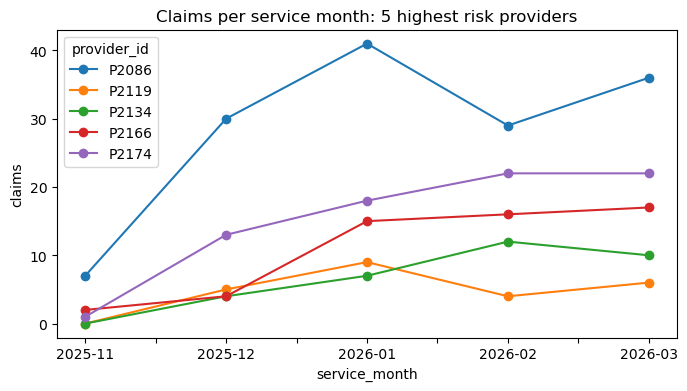

In [7]:
import matplotlib.pyplot as plt

real["service_month"] = real.service_from_date.dt.to_period("M").astype(str)
top5 = top.index[:5]
trend = (real[real.provider_id.isin(top5) & (real.service_month >= "2025-10")]
         .pivot_table(index="service_month", columns="provider_id", values="claim_id", aggfunc="count", fill_value=0))
print(trend)
trend.plot(marker="o", figsize=(8, 4), title="Claims per service month: 5 highest risk providers")
plt.ylabel("claims")
plt.show()

## Step 7: High-cost patients

Which members cost the most, and how concentrated is the cost? Only member IDs are available (no names or ages).

In [8]:
members = real.groupby("member_id").agg(
    claims=("claim_id", "count"), providers=("provider_id", "nunique"),
    total_billed=("total_billed", "sum"), total_paid=("total_paid", "sum")).sort_values("total_paid", ascending=False)
members["share_of_paid"] = members.total_paid / members.total_paid.sum()

print("Members:", len(members), "| total paid: $", round(members.total_paid.sum()))
for pct in (0.01, 0.05, 0.10):
    n = int(len(members) * pct)
    print(f"Top {int(pct*100):>2}% of members ({n}) = {members.total_paid.head(n).sum() / members.total_paid.sum():.1%} of all paid")

top_dx = real.groupby("member_id").primary_diagnosis.agg(lambda s: s.value_counts().index[0]).rename("main_diagnosis")
top_prov = real.groupby("member_id").provider_id.agg(lambda s: s.value_counts().index[0]).rename("main_provider")
high_risk = summary.index[summary.risk_level == "High"]
at_high = real[real.provider_id.isin(high_risk)].groupby("member_id").total_paid.sum().rename("paid_at_high_risk_providers")

high_cost = members.head(50).join(top_dx).join(top_prov).join(at_high)
high_cost["paid_at_high_risk_providers"] = high_cost.paid_at_high_risk_providers.fillna(0)
high_cost.round(3).head(15)

Members: 5414 | total paid: $ 7581019
Top  1% of members (54) = 26.4% of all paid
Top  5% of members (270) = 57.9% of all paid
Top 10% of members (541) = 65.3% of all paid


,claims,providers,total_billed,total_paid,share_of_paid,main_diagnosis,main_provider,paid_at_high_risk_providers
member_id,,,,,,,,
M103229,8,5,254590.37,88239.89,0.012,C18.9,P2170,0.00
M105669,6,3,189000.39,78966.41,0.010,C18.9,P2079,0.00
M101549,6,4,209189.68,72651.46,0.010,C50.911,P2032,0.00
M102464,12,10,159982.56,62787.51,0.008,C18.9,P2032,0.00
M105512,7,5,203601.65,47337.70,0.006,C34.90,P2032,0.00
M106213,9,9,90268.67,46686.38,0.006,J18.9,P2070,0.00
M106371,5,3,160294.85,43051.21,0.006,C18.9,P2032,0.00
M102447,6,5,90619.94,42954.97,0.006,J06.9,P2048,0.00
M106692,9,8,74750.73,42066.31,0.006,J06.9,P2071,777.81


In [9]:
many = members[members.providers >= 6].sort_values("providers", ascending=False)
print("Members with 6 or more different providers:", len(many))
many.round(3).head(10)

Members with 6 or more different providers: 299


,claims,providers,total_billed,total_paid,share_of_paid
member_id,,,,,
M104068,20,17,15847.21,4827.75,0.001
M101393,21,17,59096.56,33010.64,0.004
M107231,18,17,50292.14,22313.15,0.003
M106865,16,15,12134.87,3799.91,0.001
M103635,17,15,88921.51,40599.53,0.005
M101723,17,14,11560.99,4226.36,0.001
M104069,14,12,9248.84,3416.09,0.000
M106533,14,12,10723.12,5111.32,0.001
M101886,13,12,7234.10,3868.65,0.001


## Step 8: Save the results

In [10]:
OUT.mkdir(exist_ok=True)
summary.round(4).sort_values("risk_score", ascending=False).to_csv(OUT / "provider_risk_scores.csv")
high_cost.round(2).to_csv(OUT / "high_cost_patients.csv")
many.round(2).to_csv(OUT / "members_many_providers.csv")
d[d.price_outlier].drop(columns=["fence"]).to_csv(OUT / "price_outlier_lines.csv", index=False)
try:
    with pd.ExcelWriter(OUT / "risk_and_patients_draft.xlsx") as xl:
        summary.round(4).sort_values("risk_score", ascending=False).to_excel(xl, sheet_name="provider_risk_scores")
        high_cost.round(2).to_excel(xl, sheet_name="high_cost_patients")
        many.round(2).to_excel(xl, sheet_name="members_many_providers")
    print("Saved Excel file too.")
except ModuleNotFoundError:
    print("Excel file skipped (run: pip install openpyxl). CSV files were saved.")
print("Saved to", OUT.resolve())

Saved Excel file too.
Saved to C:\Users\munic\Desktop\Oriana Data Analytics Internship\Final Project\Dataset\fraud_outputs
